# Session 7 — Demo 2 — Thirty shares, three forces: PCA

**What this demo covers.** Thirty Russian shares move every week. Most of that movement has a few common causes: the whole market, oil, gold. **PCA** (principal component analysis) finds those common forces in the data, without being told about oil or gold, and compresses 30 columns into 3. We start with two shares on a flat chart and literally rotate the axes, then run PCA on all thirty, name the three components by looking at which shares load on them, and check the names against Brent and gold prices. At the end we cluster the shares themselves, and see why the market has to be taken out first.

**Data.** `data/stocks/`: daily closing prices of 30 shares on the Moscow Exchange, January 2023 to September 2026, adjusted for dividends and splits; a list of companies with sectors; four market series (the MOEX index, Brent, gold, the dollar rate). See the [data dictionary](../../data/README.md).

**How to run.** Locally: top to bottom. Colab: uncomment the two `git clone` lines in the setup cell. Everything used here is preinstalled in Colab.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

# 30 Moscow Exchange shares and four market series (session 7)
STOCKS = Path("../../data/stocks")

# --- Google Colab? Uncomment these lines to fetch the course repo: ---
# !git clone https://github.com/seemsGoodNow/hse-data-science-course.git course
# STOCKS = Path("course/data/stocks")

MAIN_COLOR = "#4a7ebb"
ACCENT_COLOR = "#c0392b"
SECTOR_COLORS = {
    "Oil and gas": "#2c3e50",
    "Gold": "#d4a017",
    "Metals and mining": "#8e44ad",
    "Steel": "#7f8c8d",
    "Banks and finance": "#4a7ebb",
    "Consumer and telecom": "#27ae60",
    "Utilities": "#16a085",
    "Transport": "#e67e22",
    "Chemicals and real estate": "#c0392b",
}

In [2]:
def make_ax_better(ax, minor=""):
    """Tidy one chart: drop the top/right frame, add a light grid.

    minor="x", "y" or "xy" also adds small ticks between the labelled ones.
    """
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    if "x" in minor:
        ax.xaxis.set_minor_locator(AutoMinorLocator())
    if "y" in minor:
        ax.yaxis.set_minor_locator(AutoMinorLocator())
    if minor:
        ax.tick_params(which="minor", length=2.5)
        ax.tick_params(which="major", length=5)
        ax.grid(which="minor", linewidth=0.15, color="tab:grey", alpha=0.25)
    ax.grid(linewidth=0.5, color="tab:grey", alpha=0.25)

## 1. The data: one column per share

`pd.read_csv` with two new arguments: `index_col="date"` makes the date column the row labels, and `parse_dates=True` turns those labels into real dates, so that session 1's `.resample` works on them.

In [3]:
prices = pd.read_csv(STOCKS / "prices.csv", index_col="date", parse_dates=True)
companies = pd.read_csv(STOCKS / "companies.csv")

print(f"{prices.shape[0]} trading days, {prices.shape[1]} shares")
prices.head()

953 trading days, 30 shares


,SBER,VTBR,BSPB,MOEX,AFKS,LKOH,ROSN,TATN,SNGS,GAZP,...,MAGN,MGNT,MTSS,RTKM,IRAO,HYDR,AFLT,FLOT,PHOR,SMLT
date,,,,,,,,,,,,,,,,,,,,,
2023-01-03,87.8190,49.9585,54.4479,60.2987,11.6089,2514.6655,262.5079,231.3056,18.7600,163.52,...,29.9880,3843.9849,129.2316,43.1890,2.3842,0.7247,19.0077,28.9642,4842.7480,2424.5
2023-01-04,87.6022,49.9130,54.3678,60.4564,11.6986,2510.0917,260.9031,230.7793,18.6700,162.51,...,29.8802,3851.4781,129.8631,43.0120,2.3783,0.7184,19.3163,29.1396,4847.9473,2428.0
2023-01-05,87.5031,49.5788,54.3251,60.4501,11.5479,2492.4064,262.1157,229.8582,18.6058,161.20,...,29.7455,3813.1308,129.6709,42.9812,2.3869,0.7176,19.7483,29.2999,4841.2625,2397.5
2023-01-06,87.5836,49.2294,54.4159,60.0715,11.4849,2493.6261,261.9730,230.6477,18.5716,162.10,...,29.9565,3807.8415,129.8631,43.0197,2.4356,0.7153,19.6403,29.2617,4818.2372,2390.0
2023-01-09,88.2030,50.0041,54.7096,60.2860,11.3323,2506.4327,262.4366,232.6338,18.5159,162.71,...,29.8667,3817.0978,130.5220,43.6738,2.4784,0.7176,20.1185,29.8187,4740.2482,2395.0


Thirty columns don't fit on the screen, so pandas hides the middle ones behind `...`. The company names and sectors are in the second file:

In [4]:
companies.head(10)

,ticker,company,sector
0,SBER,Sberbank,Banks and finance
1,VTBR,VTB Bank,Banks and finance
2,BSPB,Bank Saint Petersburg,Banks and finance
3,MOEX,Moscow Exchange,Banks and finance
4,AFKS,Sistema,Banks and finance
5,LKOH,Lukoil,Oil and gas
6,ROSN,Rosneft,Oil and gas
7,TATN,Tatneft,Oil and gas
8,SNGS,Surgutneftegas,Oil and gas
9,GAZP,Gazprom,Oil and gas


The prices are **adjusted for dividends and splits**: when a company pays a dividend, the price drops by about that amount the next morning, and the adjusted series removes that drop. So a change in the adjusted price is the full return of holding the share, dividends included.

## 2. From prices to weekly returns

We don't compare prices: Lukoil costs thousands of rubles and VTB tens, and both drift with time. We compare **returns**, the percentage change from one period to the next. `.pct_change()` computes it for every column: (this value − previous value) / previous value.

🧪 **Toy example:** a price of 100, then 110, then 99.

In [5]:
toy_price = pd.Series([100, 110, 99])
toy_price.pct_change()

0    NaN
1    0.1
2   -0.1
dtype: float64

+10%, then −10%. The first value has no previous one, so it is `NaN`.

We take **weekly** returns, not daily. Some of these shares trade thinly, and on a given day their price may lag the market by a few hours; over a week that noise averages out. `.resample("W-FRI").last()` (session 1's resample, weeks ending on Friday) keeps the last price of every week. `.dropna()` then drops the first week, which has no return.

In [6]:
weekly_returns = (
    prices
    .resample("W-FRI")
    .last()
    .pct_change()
    .dropna()
)
print(f"{len(weekly_returns)} weeks, {weekly_returns.shape[1]} shares")
weekly_returns.head().round(3)

195 weeks, 30 shares


,SBER,VTBR,BSPB,MOEX,AFKS,LKOH,ROSN,TATN,SNGS,GAZP,...,MAGN,MGNT,MTSS,RTKM,IRAO,HYDR,AFLT,FLOT,PHOR,SMLT
date,,,,,,,,,,,,,,,,,,,,,
2023-01-13,0.073,0.027,-0.007,0.040,0.044,-0.004,-0.002,0.005,0.002,0.015,...,0.021,0.070,0.011,0.017,-0.005,0.001,0.087,0.035,-0.019,0.063
2023-01-20,-0.002,0.004,-0.003,0.022,-0.027,-0.032,-0.027,-0.034,0.000,-0.035,...,-0.009,-0.010,0.003,-0.009,-0.018,-0.004,0.004,0.046,-0.006,-0.033
2023-01-27,0.012,-0.008,-0.008,0.025,0.010,-0.007,0.001,-0.002,0.072,0.001,...,0.016,0.007,0.009,0.001,0.025,0.026,-0.004,0.021,0.015,0.027
2023-02-03,0.053,0.020,0.005,0.037,0.058,-0.002,0.015,-0.027,-0.007,0.011,...,0.111,0.012,0.054,0.049,-0.003,0.005,0.005,0.129,0.039,0.022
2023-02-10,0.026,0.002,0.189,0.005,0.026,0.004,0.027,-0.001,-0.001,-0.014,...,0.009,0.004,0.010,0.004,-0.005,0.006,0.035,-0.018,0.027,0.037


Every row is a week, every column a share, every cell a return: `0.012` is +1.2%. This is a table with 30 columns, and PCA will compress it.

## 3. Two shares: rotate the axes

Start small. Lukoil and Rosneft are both oil companies, so their weekly returns should move together. First we **standardize** both columns (session 5's `(x - mean) / std`), so both have mean 0 and the same spread.

In [7]:
oil_pair = weekly_returns[["LKOH", "ROSN"]]
oil_pair_scaled = (oil_pair - oil_pair.mean()) / oil_pair.std()

print(f"correlation of weekly returns: {oil_pair.corr().loc['LKOH', 'ROSN']:.2f}")

correlation of weekly returns: 0.76


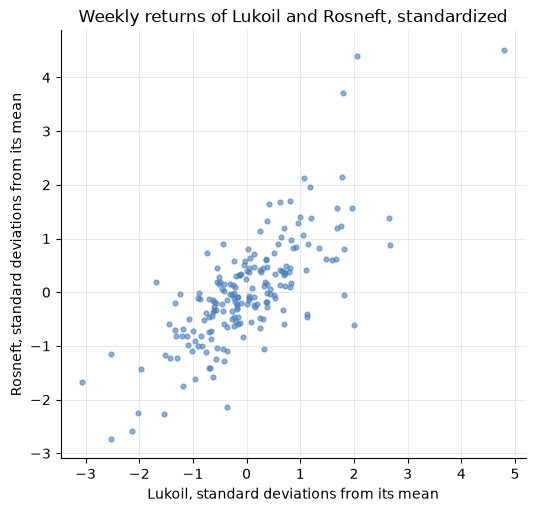

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(
    oil_pair_scaled["LKOH"],
    oil_pair_scaled["ROSN"],
    s=12,
    alpha=0.6,
    color=MAIN_COLOR,
)
ax.set_title("Weekly returns of Lukoil and Rosneft, standardized")
ax.set_xlabel("Lukoil, standard deviations from its mean")
ax.set_ylabel("Rosneft, standard deviations from its mean")
ax.set_aspect("equal")
make_ax_better(ax)
plt.show()

A correlation of 0.76: the cloud is a stretched oval along the diagonal. Most of the time, a good week for Lukoil is a good week for Rosneft.

Now the key idea. We describe each week with two numbers, "Lukoil" and "Rosneft". But we could choose **different axes**:

- **new axis 1** along the oval: "how good was the week for oil companies in general";
- **new axis 2** across the oval: "how much better did Lukoil do than Rosneft".

That is just a rotation of the chart by 45 degrees. Nothing is lost: two old numbers, two new numbers. But the spread is now very uneven. Along axis 1 the points spread widely; across, along axis 2, only a little. If we must keep one number per week, axis 1 keeps most of the information.

**That is PCA:** rotate the axes so that the first one runs along the biggest spread, the second along the biggest remaining spread at a right angle to the first, and so on. Then keep the first few. scikit-learn's `PCA` finds the axes, called **principal components**, with `.fit`.

In [9]:
from sklearn.decomposition import PCA

pair_pca = PCA(n_components=2)
pair_pca.fit(oil_pair_scaled)

pair_weights = pd.DataFrame(
    pair_pca.components_,
    columns=["LKOH", "ROSN"],
    index=["new axis 1", "new axis 2"],
)
pair_weights["share_of_spread"] = pair_pca.explained_variance_ratio_
pair_weights.round(3)

,LKOH,ROSN,share_of_spread
new axis 1,0.707,0.707,0.878
new axis 2,-0.707,0.707,0.122


Two learned attributes (they end with `_`, as in Demo 1):

- `components_`: each row is a new axis, written as **weights** of the old columns. Axis 1 is 0.707 × Lukoil + 0.707 × Rosneft: equal parts of both, "oil in general". Axis 2 is −0.707 × Lukoil + 0.707 × Rosneft: the difference. (0.707 is the cosine of 45 degrees: the rotation we guessed.)
- `explained_variance_ratio_`: the share of the total spread (variance, session 5) that lies along each axis. Axis 1 holds 88%.

The weights are called **loadings**. To get a week's position on the new axis, multiply and add, exactly as the formula says. Let's do it by hand for the first week and compare with what `PCA.transform` returns:

In [10]:
first_date = oil_pair_scaled.index[0]
by_hand = (
    pair_weights.loc["new axis 1", "LKOH"] * oil_pair_scaled.loc[first_date, "LKOH"]
    + pair_weights.loc["new axis 1", "ROSN"] * oil_pair_scaled.loc[first_date, "ROSN"]
)

# transform returns one row per week and one column per new axis;
# [0, 0] is the first week on new axis 1
by_pca = pair_pca.transform(oil_pair_scaled.head(1))[0, 0]

print(
    f"position on new axis 1, by hand: {by_hand:.4f}\n"
    f"position on new axis 1, by PCA:  {by_pca:.4f}"
)

position on new axis 1, by hand: -0.2408
position on new axis 1, by PCA:  -0.2408


The same number. "Rotating the axes" is nothing more than this weighted sum, done for every week and every axis at once. In matrix language: the table of returns times the table of weights. That is all the matrix there is.

Let's draw the new axes on the cloud:

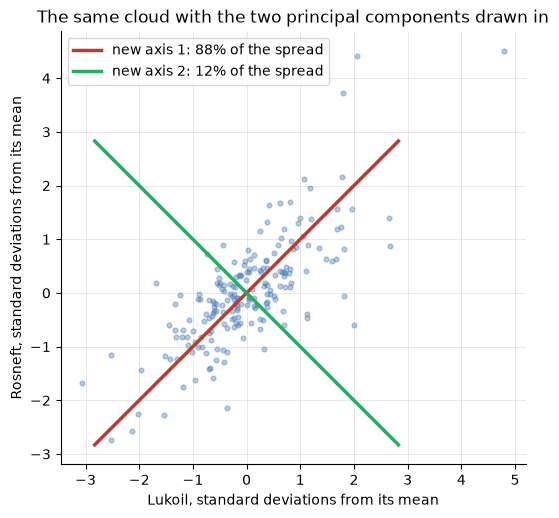

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(
    oil_pair_scaled["LKOH"],
    oil_pair_scaled["ROSN"],
    s=12,
    alpha=0.4,
    color=MAIN_COLOR,
)
for axis_name, color in [("new axis 1", ACCENT_COLOR), ("new axis 2", "#27ae60")]:
    weight_lkoh = pair_weights.loc[axis_name, "LKOH"]
    weight_rosn = pair_weights.loc[axis_name, "ROSN"]
    share = pair_weights.loc[axis_name, "share_of_spread"]
    ax.plot(
        [-4 * weight_lkoh, 4 * weight_lkoh],
        [-4 * weight_rosn, 4 * weight_rosn],
        color=color,
        linewidth=2.5,
        label=f"{axis_name}: {share:.0%} of the spread",
    )
ax.set_title("The same cloud with the two principal components drawn in")
ax.set_xlabel("Lukoil, standard deviations from its mean")
ax.set_ylabel("Rosneft, standard deviations from its mean")
ax.set_aspect("equal")
ax.legend(loc="upper left")
make_ax_better(ax)
plt.show()

The red line runs along the oval, the green one across it. Keep only the red one, and each week is described by one number instead of two, with 88% of the movement kept.

## 4. Thirty shares: how many forces?

Now the whole table. Standardize all 30 columns, ask PCA for 10 components, and look at how the spread splits between them.

One new piece of syntax for the labels: `[f"PC{number}" for number in range(1, 11)]` builds a list in one line, `PC1` to `PC10`. Read it as a `for` loop that appends each value to a list, written inside the square brackets.

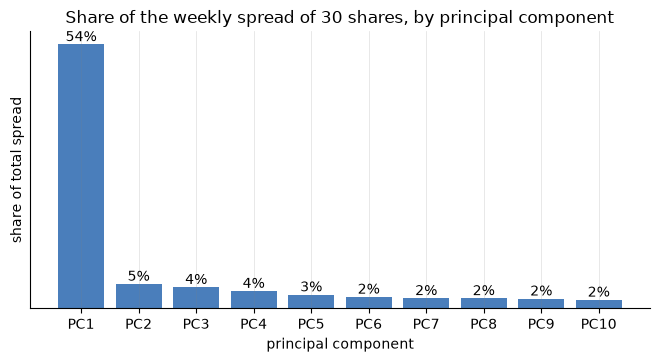

first three components together: 64%


In [12]:
returns_scaled = (weekly_returns - weekly_returns.mean()) / weekly_returns.std()

market_pca = PCA(n_components=10)
market_pca.fit(returns_scaled)

spread_share = pd.Series(
    market_pca.explained_variance_ratio_,
    index=[f"PC{number}" for number in range(1, 11)],
)

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(spread_share.index, spread_share, color=MAIN_COLOR)
ax.bar_label(bars, fmt="{:.0%}")
ax.set_title("Share of the weekly spread of 30 shares, by principal component")
ax.set_xlabel("principal component")
ax.set_ylabel("share of total spread")
ax.set_yticks([])
make_ax_better(ax)
plt.show()

print(f"first three components together: {spread_share.head(3).sum():.0%}")

One giant and a long tail. **The first component alone holds 54% of all the weekly movement of 30 shares.** Each next one holds 5% or less. With 30 shares, an average column would hold 1 / 30 = 3.3%; the first component is worth 16 columns.

We keep three: 64% of the movement, in 3 columns instead of 30. Which three forces are these? PCA doesn't know: it only found directions of big spread. **Naming them is our job, from the loadings.**

## 5. Name the forces

The loadings of a component say how much each share takes part in it. A bar per share, coloured by sector (the colour here encodes a variable: the sector).

In [13]:
loadings = pd.DataFrame(
    market_pca.components_[:3].T,
    index=weekly_returns.columns,
    columns=["PC1", "PC2", "PC3"],
)
sector_of = companies.set_index("ticker")["sector"]
loadings["sector"] = sector_of
loadings.round(2).head()

,PC1,PC2,PC3,sector
SBER,0.20,0.01,-0.10,Banks and finance
VTBR,0.17,-0.02,0.10,Banks and finance
BSPB,0.14,-0.09,0.03,Banks and finance
MOEX,0.17,-0.10,-0.11,Banks and finance
AFKS,0.19,-0.18,-0.15,Banks and finance


`components_[:3]` takes the first three rows (the first three components); `.T` flips the table so that shares become rows and components become columns.

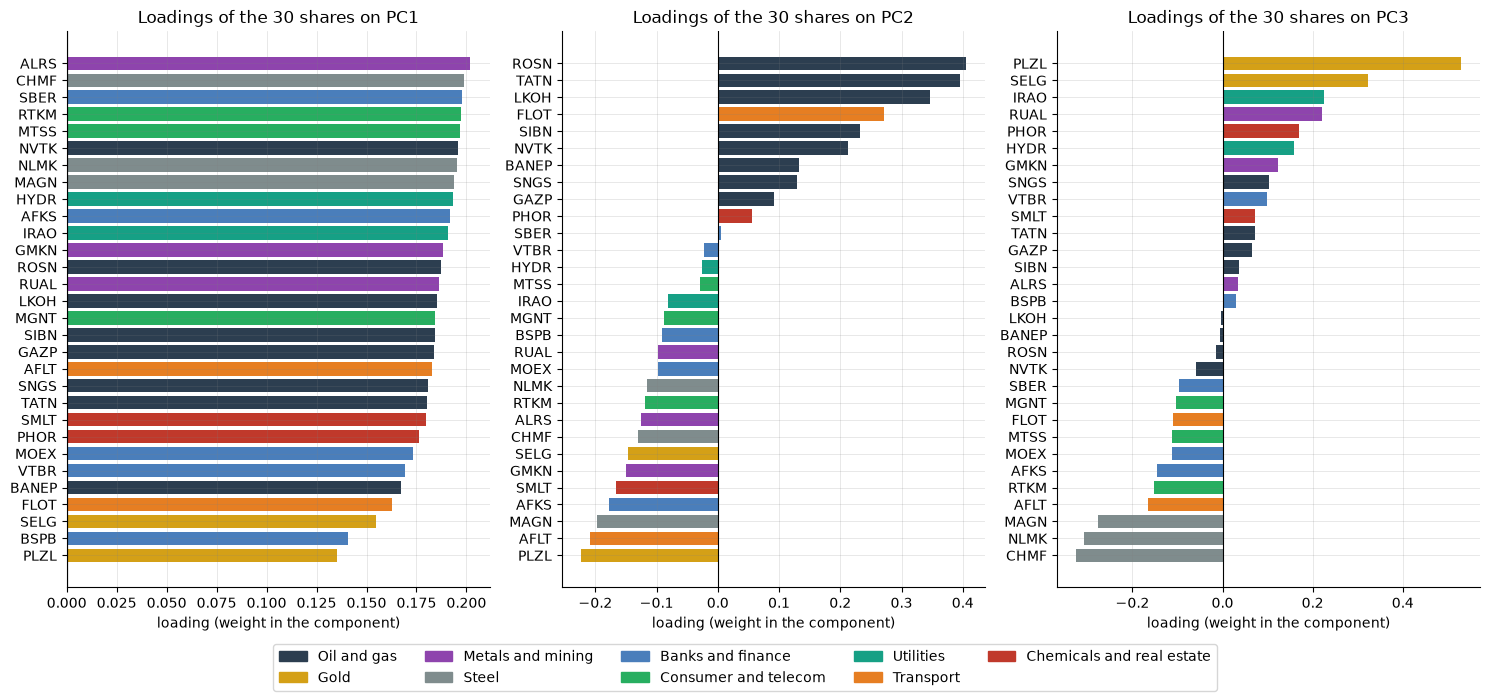

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 7), sharey=False)
for ax, component in zip(axes, ["PC1", "PC2", "PC3"]):
    sorted_loadings = loadings.sort_values(component)
    ax.barh(
        sorted_loadings.index,
        sorted_loadings[component],
        color=sorted_loadings["sector"].map(SECTOR_COLORS),
    )
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Loadings of the 30 shares on {component}")
    ax.set_xlabel("loading (weight in the component)")
    make_ax_better(ax)
legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=color)
    for color in SECTOR_COLORS.values()
]
fig.legend(
    legend_handles,
    SECTOR_COLORS.keys(),
    loc="lower center",
    ncol=5,
)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

`ax.barh` draws horizontal bars, handy when the labels are names. The legend is built by hand from small coloured rectangles, one per sector, with the same one-line list as in section 4.

Read the three panels:

- **PC1:** every share loads with the same sign and about the same size. When PC1 goes up, everything goes up together. This is **the market**: the force that moves all Russian shares at once (news, rates, sanctions, mood).
- **PC2:** oil companies (Rosneft, Tatneft, Lukoil, Sovcomflot's tankers, Gazprom Neft, Novatek) on one side; gold, steel, Aeroflot on the other. A week high on PC2 is a week when **oil companies** beat the rest.
- **PC3:** gold miners (Polyus, Seligdar) on top, steelmakers (Severstal, NLMK, MMK) at the bottom. A **gold** force, against steel.

A note on signs: PCA picks the direction of each axis arbitrarily, so a component could come out flipped, with all loadings negative. Flipping a sign changes nothing in the meaning. Here the market came out positive.

**Check the names against the world.** The file `factors.csv` holds the MOEX index, Brent oil, gold, and the dollar rate. If our names are right, each component's weekly value should move with its series. `market_pca.transform` gives every week's position on the three components.

In [15]:
factors = pd.read_csv(STOCKS / "factors.csv", index_col="date", parse_dates=True)
factor_returns = (
    factors
    .resample("W-FRI")
    .last()
    .pct_change()
    .dropna()
)

component_values = pd.DataFrame(
    market_pca.transform(returns_scaled)[:, :3],
    index=weekly_returns.index,
    columns=["PC1", "PC2", "PC3"],
)

checks = pd.concat([component_values, factor_returns], axis=1).corr()
checks.loc[
    ["PC1", "PC2", "PC3"],
    ["imoex", "brent_usd", "gold_usd", "usd_rub"],
].round(2)

,imoex,brent_usd,gold_usd,usd_rub
PC1,0.95,0.10,0.09,-0.03
PC2,0.08,0.40,-0.25,0.11
PC3,-0.03,0.07,0.30,0.01


- **PC1 and the MOEX index: 0.95.** PCA rebuilt the market index from 30 shares without ever seeing it.
- **PC2 and Brent: 0.40.** Clearly connected, far from identical. PC2 is "oil companies against the rest", and oil companies follow more than the oil price (taxes, the ruble, export routes).
- **PC3 and gold: 0.30.** The same story, weaker. PC2 also moves with gold, in the opposite direction (−0.25): the gold miners sit on the far side of PC2, so a good week for oil companies is often a weak one for gold. PC3 is what is left of gold once oil is accounted for, set against steel.
- The dollar rate barely shows up in any of the three.

So we compressed 30 columns into 3 named ones, **market**, **oil** and **gold**, which keep 64% of the weekly movement. These three columns can now be features in a regression (session 5): "how does my portfolio react to the market, to oil, to gold?" This is the idea behind **factor models** in finance. The same trick describes the whole bond yield curve with three numbers (its level, slope and bend), and helps measure the risk of a big portfolio with a few numbers instead of hundreds.

## 6. Cluster the shares themselves

Shares that move together are a natural group, and Demo 1's hierarchical clustering can draw them as a tree. The distance between two shares: **1 − correlation** of their weekly returns. Correlation 1 means distance 0; correlation 0 means distance 1.

`linkage` wants the distances as one long list, every pair once; `squareform` from SciPy converts the square table into that list. `method="average"` measures the distance between two groups as the average distance between their members.

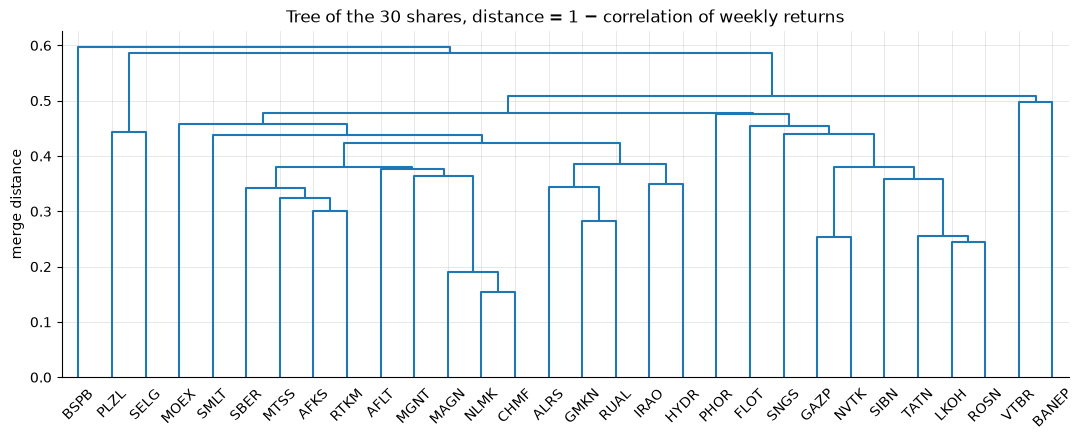

In [16]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

raw_distance = 1 - weekly_returns.corr()
raw_merges = linkage(squareform(raw_distance), method="average")

fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(
    raw_merges,
    labels=list(raw_distance.index),
    ax=ax,
    color_threshold=0,
)
ax.set_title("Tree of the 30 shares, distance = 1 − correlation of weekly returns")
ax.set_ylabel("merge distance")
make_ax_better(ax)
plt.show()

Read it from the bottom. Some groups are already visible: the oil companies merge early on the right, the three steelmakers on the left. But look at the top of the tree. The last shares to join, the "loners", are Bank Saint Petersburg, the two gold miners, VTB and Bashneft. Check the PC1 bar chart in section 5: these are the shares with the **smallest market loadings** (Sovcomflot is low on PC1 too, but still joins the oil group). They stand apart not because they form groups of their own, but because they follow the market less than everybody else.

The reason is section 5 again: **the market moves everything together.** Every pair of shares shares the market, so all distances are squeezed below 0.6, and the strongest signal in the tree is "how much does this share follow the market". The common force hides the finer groups.

**The fix: take the market out first.** PCA lets us rebuild the table from its components. Rebuild it from all components **except the first**, and what is left is each share's movement once the market is removed. `inverse_transform` turns component values back into the original columns.

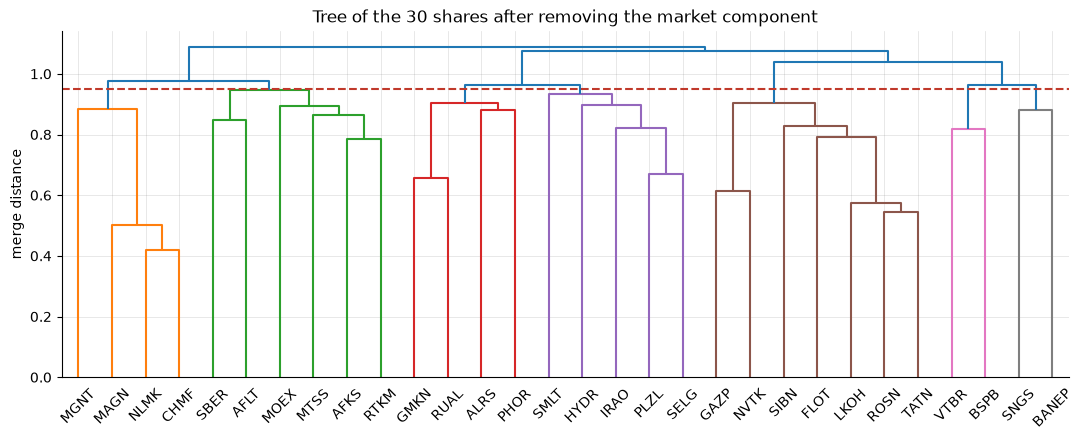

In [17]:
full_pca = PCA().fit(returns_scaled)
all_component_values = full_pca.transform(returns_scaled)

# set every week's market value to zero, then rotate back
all_component_values[:, 0] = 0
returns_without_market = pd.DataFrame(
    full_pca.inverse_transform(all_component_values),
    index=weekly_returns.index,
    columns=weekly_returns.columns,
)

clean_distance = 1 - returns_without_market.corr()
clean_merges = linkage(squareform(clean_distance, checks=False), method="average")

fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(
    clean_merges,
    labels=list(clean_distance.index),
    ax=ax,
    color_threshold=0.95,
)
ax.axhline(0.95, color=ACCENT_COLOR, linestyle="--")
ax.set_title("Tree of the 30 shares after removing the market component")
ax.set_ylabel("merge distance")
make_ax_better(ax)
plt.show()

`PCA()` without a number keeps all 30 components, so rotating back rebuilds the table exactly, minus the part we set to zero. `checks=False` tells `squareform` not to complain about tiny rounding errors on the diagonal.

The distances now run up to 1: once the market is gone, most pairs of shares are barely correlated, and only real neighbours stay close. Cut the tree at the dashed line, height 0.95, and compare the groups with the official sectors. `fcluster` cuts a tree at a given height (`criterion="distance"`).

In [18]:
share_groups = pd.Series(
    fcluster(clean_merges, t=0.95, criterion="distance"),
    index=clean_distance.index,
    name="group",
)
groups_table = (
    pd.DataFrame({"group": share_groups, "sector": sector_of})
    .sort_values(["group", "sector"])
)
for group, members in groups_table.groupby("group"):
    names = ", ".join(members.index)
    sectors = ", ".join(sorted(set(members["sector"])))
    print(f"group {group}: {names}  ({sectors})")

group 1: MGNT, NLMK, CHMF, MAGN  (Consumer and telecom, Steel)
group 2: SBER, MOEX, AFKS, MTSS, RTKM, AFLT  (Banks and finance, Consumer and telecom, Transport)
group 3: PHOR, GMKN, ALRS, RUAL  (Chemicals and real estate, Metals and mining)
group 4: SMLT, PLZL, SELG, IRAO, HYDR  (Chemicals and real estate, Gold, Utilities)
group 5: LKOH, ROSN, TATN, GAZP, NVTK, SIBN, FLOT  (Oil and gas, Transport)
group 6: VTBR, BSPB  (Banks and finance)
group 7: SNGS, BANEP  (Oil and gas)


`", ".join(list)` glues a list of words into one string with commas between them.

The tree never saw the sector column, and still:

- the **oil** companies sit together, with Sovcomflot's oil tankers among them;
- the three **steelmakers** form their own tight group;
- the **metal exporters** (Nornickel, Alrosa, Rusal) join PhosAgro, another exporter;
- **VTB and Bank Saint Petersburg**, two loners on the raw tree, now pair up as banks;
- Surgutneftegas and Bashneft, two more oil companies, pair up on their own, apart from the main oil group;
- the domestic **blue chips** (Sberbank, Moscow Exchange, MTS, Rostelecom, Aeroflot, Sistema) form a group of their own.

Some groups are a surprise: Magnit next to the steelmakers, the gold miners next to two electricity companies and a developer. That is the honest part of clustering. The algorithm reports what moved together in these 195 weeks, not what the sector list says. A surprise is a question for an analyst, not an answer.

**Lesson for any clustering:** when one strong common force drives everything, remove it first, or it hides the groups.

## 7. Where PCA stops

PCA can only **rotate** the axes and keep the straight ones. That is its strength: the components are weighted sums you can read, as we did with the loadings. It is also its limit. If the structure in the data is curved, like Demo 1's half-moons, no straight axis can unroll it.

For pictures of complex data (thousands of texts, each described by hundreds of numbers), we need methods that bend: **t-SNE** and **UMAP**. They come in Demo 3, where we compare them with PCA on the same texts.

## Try it yourself

1. Repeat section 3 with Sberbank and VTB, two banks. How much of the spread does the first axis hold? More or less than the oil pair?
2. Run section 4 on **daily** returns instead of weekly (remove the `.resample("W-FRI")` and `.last()` lines from the chain). Does the first component get bigger or smaller? Why might that be?
3. Which share has the smallest loading on PC1 (the least "market" share)? Find it in the bar chart, then check its correlation with the MOEX index.
4. 🤖 Ask an assistant: "Explain principal component analysis to a finance student using two stocks as an example." Does its explanation match section 3: a rotation, weights, share of spread?

In [19]:
# your turn

## Recap

- Compare **returns**, not prices; `.pct_change()` computes them. Weekly returns are less noisy than daily.
- **PCA rotates the axes**: the first new axis runs along the biggest spread, the next along the biggest remaining spread, and so on. Keep the first few: fewer columns, most of the movement.
- A component is a **weighted sum** of the original columns. The weights are the **loadings** (`components_`); the share of spread is `explained_variance_ratio_`. Standardize first.
- PCA finds directions, **you name them** from the loadings, and check the names against the world: PC1 = the market (0.95 with the MOEX index), PC2 = oil companies, PC3 = gold against steel. 30 columns → 3, keeping 64%.
- Clustering shares by **1 − correlation**: the market hides the groups; remove the first component and sectors appear.
- PCA is linear: it can't unroll curved shapes. For pictures of complex data, t-SNE and UMAP (Demo 3).

## ⚡ Extras — power tools, not required

**How much of each share do three components keep?** Rebuild the table from the first three components only and compare it with the original: for each share, the share of its weekly spread that the three forces explain. Shares near 1 are pure "market + oil + gold"; shares near 0 live their own life.

In [20]:
three_pca = PCA(n_components=3).fit(returns_scaled)
rebuilt = pd.DataFrame(
    three_pca.inverse_transform(three_pca.transform(returns_scaled)),
    index=weekly_returns.index,
    columns=weekly_returns.columns,
)
kept_share = 1 - ((returns_scaled - rebuilt) ** 2).sum() / (returns_scaled ** 2).sum()
kept_share.sort_values().round(2)

BSPB     0.34
VTBR     0.48
BANEP    0.48
MOEX     0.52
PHOR     0.55
SELG     0.56
FLOT     0.56
GAZP     0.57
SNGS     0.57
SMLT     0.58
MGNT     0.58
GMKN     0.63
SIBN     0.64
RUAL     0.64
HYDR     0.64
AFLT     0.65
MTSS     0.65
SBER     0.65
IRAO     0.67
AFKS     0.68
RTKM     0.69
ALRS     0.69
NVTK     0.70
PLZL     0.74
LKOH     0.74
NLMK     0.76
TATN     0.77
MAGN     0.77
CHMF     0.81
ROSN     0.82
dtype: float64

📎 Read more: [scikit-learn, PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca) and the chapter on matrix decompositions in [Yandex's ML handbook](https://contest.yandex.ru/tracks/ml/) (in Russian).